In [1]:
import torch
import torch.nn as nn
import torch.optim as optim
from torchvision import datasets, transforms
from torch.utils.data import DataLoader
import matplotlib.pyplot as plt
import math
import torch.nn.functional as F
from torch.utils.data import Subset
import numpy as np
import pandas as pd
import copy
from torch.utils.data import ConcatDataset
from IPython.display import clear_output

import torch
import torch.nn as nn
import torch.optim as optim
from torchvision import datasets, transforms
from torch.utils.data import DataLoader
import matplotlib.pyplot as plt
import math
import torch.nn.functional as F
from torch.utils.data import Subset
import numpy as np
import pandas as pd
import copy
from torch.utils.data import ConcatDataset
from torchvision.datasets import ImageFolder
from torchvision import transforms
from torch.utils.data import DataLoader
import os
from IPython.display import clear_output

from tqdm.notebook import tqdm

In [2]:
transform = transforms.Compose([transforms.ToTensor(), transforms.Normalize((0.5,), (0.5,))])
train_set = datasets.MNIST(root='./data', train=True, download=True, transform=transform)
test_set = datasets.MNIST(root='./data', train=False, download=True, transform=transform)

loader = DataLoader(train_set, batch_size=128, shuffle=True)
test_loader = DataLoader(test_set, batch_size=128, shuffle=False)

In [3]:
# import torch
# import torch.nn as nn
# import torch.optim as optim
# from torch.utils.data import DataLoader
# from torchvision import datasets, transforms
# import math

# # ==========================================
# # 1. Dataset Loading
# # Source: torchvision.datasets documentation
# # ==========================================
# transform = transforms.Compose([
#     transforms.ToTensor(), 
#     transforms.Normalize((0.5,), (0.5,))
# ])

# print("Loading MNIST dataset...")
# train_set = datasets.MNIST(root='./data', train=True, download=True, transform=transform)
# test_set = datasets.MNIST(root='./data', train=False, download=True, transform=transform)

# loader = DataLoader(train_set, batch_size=128, shuffle=True, drop_last=True)
# test_loader = DataLoader(test_set, batch_size=128, shuffle=False)

# # ==========================================
# # 2. DDPM Forward Noise Function
# # Source: Ho et al., 2020 (Denoising Diffusion Probabilistic Models)
# # ==========================================
# def add_ddpm_noise(x_0, t, alpha_bar):
#     """
#     Corrupts clean images x_0 to timestep t using the DDPM forward process.
#     """
#     a_bar = alpha_bar[t].view(-1, 1, 1, 1)
#     noise = torch.randn_like(x_0)
#     x_t = torch.sqrt(a_bar) * x_0 + torch.sqrt(1.0 - a_bar) * noise
#     return x_t, noise

# # ==========================================
# # 3. Timestep Embedding
# # ==========================================
# class SinusoidalPositionEmbeddings(nn.Module):
#     """
#     Generates sinusoidal embeddings for timesteps.
#     """
#     def __init__(self, dim):
#         super().__init__()
#         self.dim = dim

#     def forward(self, time):
#         device = time.device
#         half_dim = self.dim // 2
#         embeddings = math.log(10000) / (half_dim - 1)
#         embeddings = torch.exp(torch.arange(half_dim, device=device) * -embeddings)
#         embeddings = time[:, None] * embeddings[None, :]
#         embeddings = torch.cat((embeddings.sin(), embeddings.cos()), dim=-1)
#         return embeddings

# # ==========================================
# # 4. Autoencoder Architecture with Time
# # ==========================================
# class ConvAutoencoder(nn.Module):
#     def __init__(self, latent_dim=128, time_emb_dim=128):
#         super().__init__()

#         # -------- Time Embedding MLP --------
#         self.time_mlp = nn.Sequential(
#             SinusoidalPositionEmbeddings(time_emb_dim),
#             nn.Linear(time_emb_dim, time_emb_dim),
#             nn.GELU(),
#             nn.Linear(time_emb_dim, time_emb_dim)
#         )

#         # Time projectors for Encoder
#         self.time_emb_enc1 = nn.Linear(time_emb_dim, 32)
#         self.time_emb_enc2 = nn.Linear(time_emb_dim, 64)
#         self.time_emb_enc3 = nn.Linear(time_emb_dim, 128)

#         # Time projectors for Decoder
#         self.time_emb_dec1 = nn.Linear(time_emb_dim, 128)
#         self.time_emb_dec2 = nn.Linear(time_emb_dim, 64)
#         self.time_emb_dec3 = nn.Linear(time_emb_dim, 32)

#         # -------- Encoder --------
#         # Changed input to 1 channel for MNIST
#         self.enc_conv1 = nn.Conv2d(1, 32, 3, stride=2, padding=1)  # B, 32, 14, 14
#         self.enc_conv2 = nn.Conv2d(32, 64, 3, stride=2, padding=1) # B, 64, 7, 7
#         self.enc_conv3 = nn.Conv2d(64, 128, 3, stride=2, padding=1)# B, 128, 4, 4

#         self.flatten = nn.Flatten()
#         self.fc_enc = nn.Linear(128 * 4 * 4, latent_dim)

#         # -------- Decoder --------
#         self.fc_dec = nn.Linear(latent_dim, 128 * 4 * 4)

#         # Adjusted output_padding to reconstruct 28x28 perfectly
#         self.dec_conv1 = nn.ConvTranspose2d(128, 64, 3, stride=2, padding=1, output_padding=0) # 7x7
#         self.dec_conv2 = nn.ConvTranspose2d(64, 32, 3, stride=2, padding=1, output_padding=1)  # 14x14
#         # Changed output to 1 channel
#         self.dec_conv3 = nn.ConvTranspose2d(32, 1, 3, stride=2, padding=1, output_padding=1)   # 28x28

#         self.relu = nn.ReLU()
#         self.tanh = nn.Tanh()

#     def encode(self, x, t):
#         t_emb = self.time_mlp(t)

#         x = self.enc_conv1(x)
#         x = x + self.time_emb_enc1(t_emb).view(-1, 32, 1, 1)
#         x = self.relu(x)

#         x = self.enc_conv2(x)
#         x = x + self.time_emb_enc2(t_emb).view(-1, 64, 1, 1)
#         x = self.relu(x)

#         x = self.enc_conv3(x)
#         x = x + self.time_emb_enc3(t_emb).view(-1, 128, 1, 1)
#         x = self.relu(x)

#         x = self.flatten(x)
#         z = self.fc_enc(x)
#         return z, t_emb

#     def decode(self, z, t_emb):
#         x = self.fc_dec(z)
#         x = x.view(-1, 128, 4, 4)

#         x = x + self.time_emb_dec1(t_emb).view(-1, 128, 1, 1)
#         x = self.dec_conv1(x)
#         x = self.relu(x)

#         x = x + self.time_emb_dec2(t_emb).view(-1, 64, 1, 1)
#         x = self.dec_conv2(x)
#         x = self.relu(x)

#         x = x + self.time_emb_dec3(t_emb).view(-1, 32, 1, 1)
#         x = self.dec_conv3(x)
#         x = self.tanh(x)

#         return x

#     def forward(self, x, t):
#         z, t_emb = self.encode(x, t)
#         out = self.decode(z, t_emb)
#         return out

# # ==========================================
# # 5. Training Loop
# # ==========================================
# device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
# print(f"Using device: {device}")

# # Model initialized here so it moves to the correct device immediately
# model = ConvAutoencoder().to(device)


# def main():
    
    
#     optimizer = optim.Adam(model.parameters(), lr=1e-3)
#     criterion = nn.MSELoss()

#     epochs = 10
#     T = 500  # Number of diffusion steps
    
#     # Set up the DDPM forward schedule
#     beta = torch.linspace(1e-4, 0.02, T).to(device)
#     alpha = 1.0 - beta
#     alpha_bar = torch.cumprod(alpha, dim=0).to(device)

#     print("Starting training...")

#     model.train()
#     for epoch in range(epochs):
#         total_loss = 0.0
        
#         for batch_idx, (clean_images, _) in enumerate(loader):
#             clean_images = clean_images.to(device)
#             batch_size = clean_images.shape[0]
            
#             # 1. Sample random timesteps uniformly for each image in the batch
#             t = torch.randint(0, T, (batch_size,), device=device).long()
            
#             # 2. Add noise according to the DDPM schedule
#             noisy_images, _ = add_ddpm_noise(clean_images, t, alpha_bar)
            
#             # 3. Forward pass: autoencoder processes the noisy image AND timestep
#             optimizer.zero_grad()
#             reconstructed = model(noisy_images, t / T)
            
#             # 4. Calculate loss against the original CLEAN image
#             loss = criterion(reconstructed, clean_images)
            
#             # 5. Backward pass and optimize
#             loss.backward()
#             optimizer.step()
            
#             total_loss += loss.item()
            
#         avg_loss = total_loss / len(loader)
#         print(f"Epoch [{epoch+1}/{epochs}], Loss: {avg_loss:.4f}")
        
#     print("Training complete. You can now use model.encode(images, t) to extract the latent space.")

# if __name__ == "__main__":
#     main()

In [5]:
# torch.save(model.state_dict(), 'latent.pt')
class SinusoidalPositionEmbeddings(nn.Module):
    """
    Generates sinusoidal embeddings for timesteps.
    """
    def __init__(self, dim):
        super().__init__()
        self.dim = dim

    def forward(self, time):
        device = time.device
        half_dim = self.dim // 2
        embeddings = math.log(10000) / (half_dim - 1)
        embeddings = torch.exp(torch.arange(half_dim, device=device) * -embeddings)
        embeddings = time[:, None] * embeddings[None, :]
        embeddings = torch.cat((embeddings.sin(), embeddings.cos()), dim=-1)
        return embeddings

# ==========================================
# 4. Autoencoder Architecture with Time
# ==========================================
class ConvAutoencoder(nn.Module):
    def __init__(self, latent_dim=128, time_emb_dim=128):
        super().__init__()

        # -------- Time Embedding MLP --------
        self.time_mlp = nn.Sequential(
            SinusoidalPositionEmbeddings(time_emb_dim),
            nn.Linear(time_emb_dim, time_emb_dim),
            nn.GELU(),
            nn.Linear(time_emb_dim, time_emb_dim)
        )

        # Time projectors for Encoder
        self.time_emb_enc1 = nn.Linear(time_emb_dim, 32)
        self.time_emb_enc2 = nn.Linear(time_emb_dim, 64)
        self.time_emb_enc3 = nn.Linear(time_emb_dim, 128)

        # Time projectors for Decoder
        self.time_emb_dec1 = nn.Linear(time_emb_dim, 128)
        self.time_emb_dec2 = nn.Linear(time_emb_dim, 64)
        self.time_emb_dec3 = nn.Linear(time_emb_dim, 32)

        # -------- Encoder --------
        # Changed input to 1 channel for MNIST
        self.enc_conv1 = nn.Conv2d(1, 32, 3, stride=2, padding=1)  # B, 32, 14, 14
        self.enc_conv2 = nn.Conv2d(32, 64, 3, stride=2, padding=1) # B, 64, 7, 7
        self.enc_conv3 = nn.Conv2d(64, 128, 3, stride=2, padding=1)# B, 128, 4, 4

        self.flatten = nn.Flatten()
        self.fc_enc = nn.Linear(128 * 4 * 4, latent_dim)

        # -------- Decoder --------
        self.fc_dec = nn.Linear(latent_dim, 128 * 4 * 4)

        # Adjusted output_padding to reconstruct 28x28 perfectly
        self.dec_conv1 = nn.ConvTranspose2d(128, 64, 3, stride=2, padding=1, output_padding=0) # 7x7
        self.dec_conv2 = nn.ConvTranspose2d(64, 32, 3, stride=2, padding=1, output_padding=1)  # 14x14
        # Changed output to 1 channel
        self.dec_conv3 = nn.ConvTranspose2d(32, 1, 3, stride=2, padding=1, output_padding=1)   # 28x28

        self.relu = nn.ReLU()
        self.tanh = nn.Tanh()

    def encode(self, x, t):
        t_emb = self.time_mlp(t)

        x = self.enc_conv1(x)
        x = x + self.time_emb_enc1(t_emb).view(-1, 32, 1, 1)
        x = self.relu(x)

        x = self.enc_conv2(x)
        x = x + self.time_emb_enc2(t_emb).view(-1, 64, 1, 1)
        x = self.relu(x)

        x = self.enc_conv3(x)
        x = x + self.time_emb_enc3(t_emb).view(-1, 128, 1, 1)
        x = self.relu(x)

        x = self.flatten(x)
        z = self.fc_enc(x)
        return z, t_emb

    def decode(self, z, t_emb):
        x = self.fc_dec(z)
        x = x.view(-1, 128, 4, 4)

        x = x + self.time_emb_dec1(t_emb).view(-1, 128, 1, 1)
        x = self.dec_conv1(x)
        x = self.relu(x)

        x = x + self.time_emb_dec2(t_emb).view(-1, 64, 1, 1)
        x = self.dec_conv2(x)
        x = self.relu(x)

        x = x + self.time_emb_dec3(t_emb).view(-1, 32, 1, 1)
        x = self.dec_conv3(x)
        x = self.tanh(x)

        return x

    def forward(self, x, t):
        z, t_emb = self.encode(x, t)
        out = self.decode(z, t_emb)
        return out

encoder = ConvAutoencoder().to("cuda")
        
encoder.load_state_dict(torch.load('latent.pt'))

<All keys matched successfully>

In [69]:
def sample_timesteps(batch_size, diffusion_steps, power=2.0):
    u = torch.rand(batch_size, 1)
    t = (u ** power * diffusion_steps).long()
    return t

In [70]:
all_numbers, all_labels = next(iter(DataLoader(train_set, batch_size=10000, shuffle=True)))
all_numbers, all_labels = all_numbers.cuda(), all_labels.cuda()
cond_numbers = train_set.data[train_set.targets == 8].cuda().unsqueeze(1) / 255
cond_numbers = (cond_numbers - 0.5) / 0.5


In [71]:
img_size = 28
batch_size = 128
epochs = 100
timesteps = 500
img_size = 28
device = "cuda"

beta = torch.linspace(1e-4, 0.02, timesteps).to(device)
alpha = 1. - beta
alpha_bar = torch.cumprod(alpha, dim=0)

In [72]:
beta = torch.linspace(1e-4, 0.02, timesteps).to(device)
alpha = 1. - beta
alpha_bar = torch.cumprod(alpha, dim=0)


B = all_numbers.shape[0]
all_t = sample_timesteps(B, timesteps)
noise = torch.randn_like(all_numbers)
a_bar = alpha_bar[all_t].view(-1, 1, 1, 1)

all_numbers = torch.sqrt(a_bar) * all_numbers + torch.sqrt(1 - a_bar) * noise

B = cond_numbers.shape[0]
cond_t = sample_timesteps(B, timesteps)
noise = torch.randn_like(cond_numbers)
a_bar = alpha_bar[cond_t].view(-1, 1, 1, 1)

cond_numbers = torch.sqrt(a_bar) * cond_numbers + torch.sqrt(1 - a_bar) * noise


In [73]:
with torch.no_grad():
    phi_all, _ = encoder.encode(all_numbers, all_t.cuda())
    phi_eight, _ = encoder.encode(cond_numbers, cond_t.cuda())


n_de = phi_all.shape[0]
n_nu = phi_eight.shape[0]
reg = 0.01

H = (phi_all.T @ phi_all) / n_de
H += reg * torch.eye(128).to("cuda")

h = torch.mean(phi_eight, dim=0, keepdim=True).T

theta = torch.linalg.solve(H, h).clamp(min=0)

In [74]:
class BinaryClassifier(nn.Module):
    def __init__(self):
        super().__init__()

        self.features = nn.Sequential(
            nn.Conv2d(1, 64, kernel_size=3, padding=1),
            nn.GroupNorm(32, 64), nn.ReLU(), nn.MaxPool2d(2),
            
            nn.Conv2d(64, 128, kernel_size=3, padding=1),
            nn.GroupNorm(32, 128), nn.ReLU(), nn.MaxPool2d(2),
            
            nn.Conv2d(128, 256, kernel_size=3, padding=1),
            nn.GroupNorm(32, 256), nn.ReLU(), nn.MaxPool2d(2),
            
            nn.Conv2d(256, 512, kernel_size=3, padding=1),
            nn.GroupNorm(32, 512), nn.ReLU(), nn.MaxPool2d(2),
            
            nn.AdaptiveAvgPool2d((1, 1)),
            nn.Flatten()
        )
        
        self.time_mlp = nn.Sequential(
            nn.Linear(1, 128),
            nn.ReLU(),
            nn.Linear(128, 128)
        )
        
        self.fc = nn.Linear(512 + 128, 2)

    def forward(self, x, t):
        img_feats = self.features(x)
        
        if t.dim() == 1:
            t = t.unsqueeze(-1).float()
            
        time_feats = self.time_mlp(t)
        
        combined = torch.cat([img_feats, time_feats], dim=1)
        return self.fc(combined)


class DoubleConv(nn.Module):
    def __init__(self, in_channels, out_channels, groups=8):
        super().__init__()
        self.double_conv = nn.Sequential(
            nn.Conv2d(in_channels, out_channels, kernel_size=3, padding=1, bias=False),
            nn.GroupNorm(groups, out_channels),  # GroupNorm is standard for Diffusion
            nn.ReLU(inplace=True),
            nn.Conv2d(out_channels, out_channels, kernel_size=3, padding=1, bias=False),
            nn.GroupNorm(groups, out_channels),
            nn.ReLU(inplace=True)
        )

    def forward(self, x):
        return self.double_conv(x)

class uNet(nn.Module):
    def __init__(self, time_dim=128):
        super().__init__()
        self.time_mlp = nn.Sequential(
            nn.Linear(1, time_dim),
            nn.SiLU(),
            nn.Linear(time_dim, time_dim)
        )

        self.input = DoubleConv(1, 64)
        self.down1 = nn.Sequential(nn.MaxPool2d(2), DoubleConv(64, 128))
        self.down2 = nn.Sequential(nn.MaxPool2d(2), DoubleConv(128, 256))

        self.bottleneck = DoubleConv(256, 512)

        self.up1 = nn.ConvTranspose2d(512, 256, kernel_size=2, stride=2)
        self.conv_up1 = DoubleConv(384, 256)
        
        self.up2 = nn.ConvTranspose2d(256, 128, kernel_size=2, stride=2)
        self.conv_up2 = DoubleConv(192, 128)

        self.output = nn.Conv2d(128, 1, kernel_size=1)

        self.emb_down1 = nn.Linear(time_dim, 128)
        self.emb_down2 = nn.Linear(time_dim, 256)
        self.emb_up1 = nn.Linear(time_dim, 256)
        self.emb_up2 = nn.Linear(time_dim, 128)

    def forward(self, x, t):
        t = t.view(-1, 1) 
        emb = self.time_mlp(t)
        
        x1 = self.input(x)
        
        x2 = self.down1(x1)
        x2 = x2 + self.emb_down1(emb)[:, :, None, None]
        
        x3 = self.down2(x2)
        x3 = x3 + self.emb_down2(emb)[:, :, None, None]

        x_mid = self.bottleneck(x3)

        x_up1 = self.up1(x_mid)
        x_up1 = torch.cat([x_up1, x2], dim=1)
        x_up1 = self.conv_up1(x_up1) 
        x_up1 = x_up1 + self.emb_up1(emb)[:, :, None, None]
        
        x_up2 = self.up2(x_up1)
        x_up2 = torch.cat([x_up2, x1], dim=1)
        x_up2 = self.conv_up2(x_up2)
        x_up2 = x_up2 + self.emb_up2(emb)[:, :, None, None]

        return self.output(x_up2)

class Classifier(nn.Module):
    def __init__(self):
        super().__init__()

        self.features = nn.Sequential(
            nn.Conv2d(1, 64, 3, padding=1),
            nn.GroupNorm(16, 64),
            nn.ReLU(),
            nn.MaxPool2d(2),
            nn.Dropout2d(0.1),

            nn.Conv2d(64, 128, 3, padding=1),
            nn.GroupNorm(16, 128),
            nn.ReLU(),
            nn.MaxPool2d(2),
            nn.Dropout2d(0.2),

            nn.Conv2d(128, 256, 3, padding=1),
            nn.GroupNorm(16, 256),
            nn.ReLU(),
            nn.MaxPool2d(2),
            nn.Dropout2d(0.3),

            nn.AdaptiveAvgPool2d(1),
            nn.Flatten()
        )

        self.fc = nn.Linear(256, 10)

    def forward(self, x):
        x = self.features(x)
        return self.fc(x)

In [75]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
biCls = BinaryClassifier().to(device)
cls = Classifier().to(device)
model = uNet().to(device)

biCls.load_state_dict(torch.load("8_binary_clsf.pth", map_location=device))
cls.load_state_dict(torch.load("mnist_cnn_wei.pth", map_location=device))
model.load_state_dict(torch.load("uncond_diff_wei.pth", map_location=device))

<All keys matched successfully>

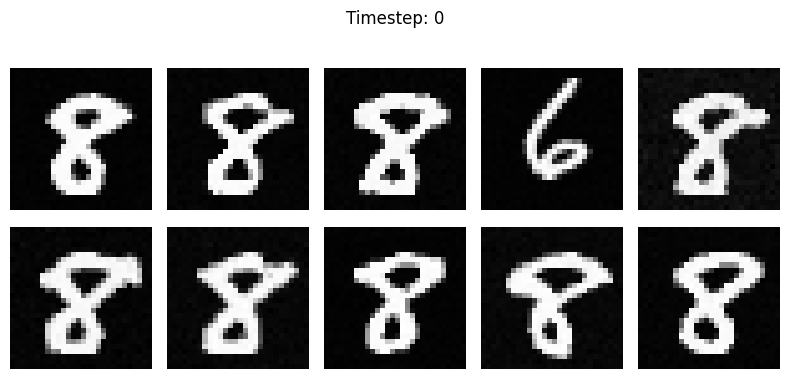

In [78]:
import matplotlib.pyplot as plt
from IPython.display import clear_output, display

# ... (Previous code: model, encoder, theta, alpha, beta setup) ...

n_samples = 50
s = 50  # Set scale > 0 to see the guidance effect
img_size = 28
device = "cuda"

# Start with random noise
xt = torch.randn(n_samples, 1, img_size, img_size).to(device)

for i in reversed(range(timesteps)):
    t = torch.tensor([i] * n_samples, device=device)
    t_float = t.float() / timesteps
    
    # 1. Unconditional prediction (no grad needed)
    with torch.no_grad():
        eps_pred = model(xt, t_float)
    
    alpha_t = alpha[i]
    alpha_bar_t = alpha_bar[i]
    beta_t = beta[i]

    # Standard Diffusion Mean
    mean = (xt - ((1 - alpha_t) / torch.sqrt(1 - alpha_bar_t)) * eps_pred) / torch.sqrt(alpha_t)

    B, C, H, W = xt.shape

    sample_t_norm = t.float().view(xt.shape[0], 1, 1, 1) / 500.0
    sample_t_channel = sample_t_norm.expand(-1, -1, H, W).cuda()

    # 2. uLSIF Guidance (Requires Grad)
    # Use a clone that tracks gradients
    xt_for_grad = xt.detach().requires_grad_(True)

    
    features, _ = encoder.encode(xt_for_grad, t_float.cuda())
    ratio = features @ theta
    log_r = torch.log(torch.clamp(ratio, min=1e-8))
    
    # Calculate gradient of log-ratio w.r.t xt
    guide_score = torch.autograd.grad(log_r.sum(), xt_for_grad)[0]
    
    # Update mean with guidance
    mean = mean + s * beta_t * guide_score.clamp(-1,1)
    
    # 3. Step to next xt-1
    if i > 0:
        noise = torch.randn_like(xt)
        xt = mean + torch.sqrt(beta_t) * noise
    else:
        xt = mean

    # 4. Live Plotting
    if i % 20 == 0 or i == 0:
        clear_output(wait=True)
    
        imgs = xt[:10].detach().cpu()
    
        fig, axes = plt.subplots(2, 5, figsize=(8, 4))
        axes = axes.flatten()
    
        for j in range(10):
            axes[j].imshow(imgs[j, 0].numpy(), cmap='gray')
            axes[j].axis('off')
    
        plt.suptitle(f"Timestep: {i}")
        plt.tight_layout()
        plt.show()

s: {} complete 0


(-0.5, 223.5, 223.5, -0.5)

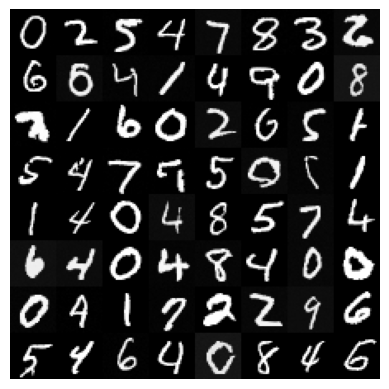

In [66]:
n_samples = 64
s = 0
final = []

xt = torch.randn(n_samples, 1, img_size, img_size).to(device)

for i in reversed(range(timesteps)):
    t = torch.tensor([i] * n_samples, device=device)
    t_float = t.float() / timesteps
    
    with torch.no_grad():
        eps_pred = model(xt, t_float)
    
    alpha_t = alpha[i]
    alpha_bar_t = alpha_bar[i]
    beta_t = beta[i]

    mean = (xt - ((1 - alpha_t) / torch.sqrt(1 - alpha_bar_t)) * eps_pred) / torch.sqrt(alpha_t)

    B, C, H, W = xt.shape

    sample_t_norm = t.float().view(xt.shape[0], 1, 1, 1) / 500.0
    sample_t_channel = sample_t_norm.expand(-1, -1, H, W).cuda()

    # 2. uLSIF Guidance (Requires Grad)
    # Use a clone that tracks gradients
    xt_for_grad = xt.detach().requires_grad_(True)

    
    features, _ = encoder.encode(xt_for_grad, t_float.cuda())
    ratio = features @ theta
    log_r = torch.log(torch.clamp(ratio, min=1e-8))
    
    # Calculate gradient of log-ratio w.r.t xt
    guide_score = torch.autograd.grad(log_r.sum(), xt_for_grad)[0]
    
    # Update mean with guidance
    mean = mean + s * beta_t * guide_score.clamp(-1,1)
    # 3. Step to next xt-1
    if i > 0:
        noise = torch.randn_like(xt)
        xt = mean + torch.sqrt(beta_t) * noise
    else:
        xt = mean

xt = xt.cpu()
print("s: {} complete", s)

torch.concat([xt[i] for i in range(xt.shape[0])], dim =1).shape

img = torch.tensor([])
for row in xt.split(8):
    img_row = torch.concat([row[i] for i in range(row.shape[0])], dim =1).clamp(-1,1)
    img = torch.cat([img, img_row], dim=-1)

plt.imshow(img[0],cmap="gray")
plt.axis('off')

s: {} complete 30


(-0.5, 223.5, 223.5, -0.5)

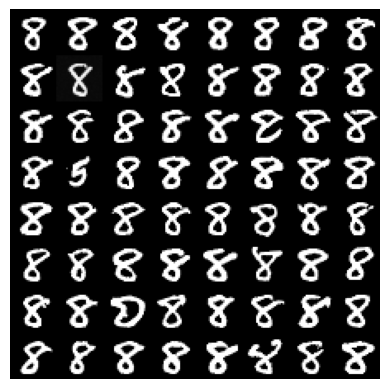

In [79]:
n_samples = 64
s = 30
final = []

xt = torch.randn(n_samples, 1, img_size, img_size).to(device)

for i in reversed(range(timesteps)):
    t = torch.tensor([i] * n_samples, device=device)
    t_float = t.float() / timesteps
    
    with torch.no_grad():
        eps_pred = model(xt, t_float)
    
    alpha_t = alpha[i]
    alpha_bar_t = alpha_bar[i]
    beta_t = beta[i]

    mean = (xt - ((1 - alpha_t) / torch.sqrt(1 - alpha_bar_t)) * eps_pred) / torch.sqrt(alpha_t)

    B, C, H, W = xt.shape

    sample_t_norm = t.float().view(xt.shape[0], 1, 1, 1) / 500.0
    sample_t_channel = sample_t_norm.expand(-1, -1, H, W).cuda()

    # 2. uLSIF Guidance (Requires Grad)
    # Use a clone that tracks gradients
    xt_for_grad = xt.detach().requires_grad_(True)

    
    features, _ = encoder.encode(xt_for_grad, t_float.cuda())
    ratio = features @ theta
    log_r = torch.log(torch.clamp(ratio, min=1e-8))
    
    # Calculate gradient of log-ratio w.r.t xt
    guide_score = torch.autograd.grad(log_r.sum(), xt_for_grad)[0]
    
    # Update mean with guidance
    mean = mean + s * beta_t * guide_score.clamp(-1,1)
    
    # 3. Step to next xt-1
    if i > 0:
        noise = torch.randn_like(xt)
        xt = mean + torch.sqrt(beta_t) * noise
    else:
        xt = mean

xt = xt.cpu()
print("s: {} complete", s)

torch.concat([xt[i] for i in range(xt.shape[0])], dim =1).shape

img = torch.tensor([])
for row in xt.split(8):
    img_row = torch.concat([row[i] for i in range(row.shape[0])], dim =1).clamp(-1,1)
    img = torch.cat([img, img_row], dim=-1)

plt.imshow(img[0],cmap="gray")
plt.axis('off')

In [84]:
n_samples = 4
s = 0
final = []

xt_hist = []

xt = torch.randn(n_samples, 1, img_size, img_size).to(device)
xt_hist.append(xt)

for i in reversed(range(timesteps)):
    t = torch.tensor([i] * n_samples, device=device)
    t_float = t.float() / timesteps
    
    with torch.no_grad():
        eps_pred = model(xt, t_float)
    
    alpha_t = alpha[i]
    alpha_bar_t = alpha_bar[i]
    beta_t = beta[i]

    mean = (xt - ((1 - alpha_t) / torch.sqrt(1 - alpha_bar_t)) * eps_pred) / torch.sqrt(alpha_t)

    if i in [375, 250, 125]:
        xt_hist.append(xt)
            
    B, C, H, W = xt.shape

    sample_t_norm = t.float().view(xt.shape[0], 1, 1, 1) / 500.0
    sample_t_channel = sample_t_norm.expand(-1, -1, H, W).cuda()

    # 2. uLSIF Guidance (Requires Grad)
    # Use a clone that tracks gradients
    xt_for_grad = xt.detach().requires_grad_(True)

    
    features, _ = encoder.encode(xt_for_grad, t_float.cuda())
    ratio = features @ theta
    log_r = torch.log(torch.clamp(ratio, min=1e-8))
    
    # Calculate gradient of log-ratio w.r.t xt
    guide_score = torch.autograd.grad(log_r.sum(), xt_for_grad)[0]
    
    # Update mean with guidance
    mean = mean + s * beta_t * torch.tanh(guide_score)
    
    if i > 0:
        noise = torch.randn_like(xt)
        xt = mean + torch.sqrt(beta_t) * noise
    else:
        xt = mean

xt = xt.cpu()

xt_hist.append(xt)

In [85]:
images = []
for xt in xt_hist:
    img = torch.tensor([])
    for row in xt.cpu().split(2):
        img_row = torch.concat([row[i] for i in range(row.shape[0])], dim =1).cpu()
        img = torch.cat([img, img_row], dim=-1)
    images.append((img.permute(1,2,0) * 0.5 + 0.5).clamp(0, 1))

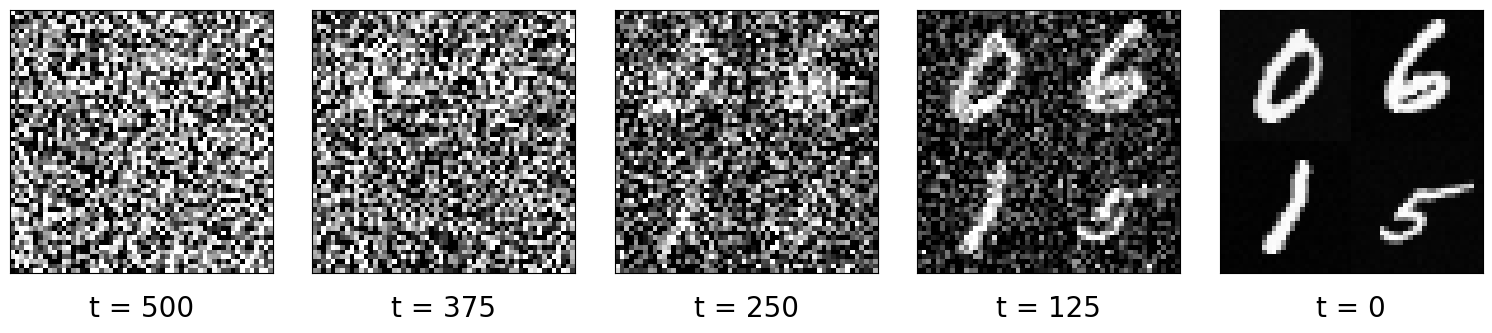

In [86]:
import matplotlib.pyplot as plt

n = len(images)

fig, axes = plt.subplots(1, n, figsize=(3.8*n, 4.5))

if n == 1:
    axes = [axes]

for i, (ax, img) in enumerate(zip(axes, images)):
    ax.imshow(img, cmap="gray")

    # Remove ticks but keep clean frame spacing
    ax.set_xticks([])
    ax.set_yticks([])

    # Caption under plot
    ax.set_title(f"t = {([500, 375, 250, 125, 0])[i]}", y=-0.2, fontsize=20)

# Better spacing between plots + room for captions
plt.subplots_adjust(wspace=0.15, bottom=0.25)

plt.show()

In [87]:
n_samples = 4
s = 30
final = []

xt_hist = []

xt = torch.randn(n_samples, 1, img_size, img_size).to(device)
xt_hist.append(xt)

for i in reversed(range(timesteps)):
    t = torch.tensor([i] * n_samples, device=device)
    t_float = t.float() / timesteps
    
    with torch.no_grad():
        eps_pred = model(xt, t_float)
    
    alpha_t = alpha[i]
    alpha_bar_t = alpha_bar[i]
    beta_t = beta[i]

    mean = (xt - ((1 - alpha_t) / torch.sqrt(1 - alpha_bar_t)) * eps_pred) / torch.sqrt(alpha_t)

    if i in [375, 250, 125]:
        xt_hist.append(xt)
            
    B, C, H, W = xt.shape

    sample_t_norm = t.float().view(xt.shape[0], 1, 1, 1) / 500.0
    sample_t_channel = sample_t_norm.expand(-1, -1, H, W).cuda()

    # 2. uLSIF Guidance (Requires Grad)
    # Use a clone that tracks gradients
    xt_for_grad = xt.detach().requires_grad_(True)

    
    features, _ = encoder.encode(xt_for_grad, t_float.cuda())
    ratio = features @ theta
    log_r = torch.log(torch.clamp(ratio, min=1e-8))
    
    # Calculate gradient of log-ratio w.r.t xt
    guide_score = torch.autograd.grad(log_r.sum(), xt_for_grad)[0]
    
    # Update mean with guidance
    mean = mean + s * beta_t * torch.tanh(guide_score)
    
    if i > 0:
        noise = torch.randn_like(xt)
        xt = mean + torch.sqrt(beta_t) * noise
    else:
        xt = mean

xt = xt.cpu()

xt_hist.append(xt)

In [88]:
images = []
for xt in xt_hist:
    img = torch.tensor([])
    for row in xt.cpu().split(2):
        img_row = torch.concat([row[i] for i in range(row.shape[0])], dim =1).cpu()
        img = torch.cat([img, img_row], dim=-1)
    images.append((img.permute(1,2,0) * 0.5 + 0.5).clamp(0, 1))

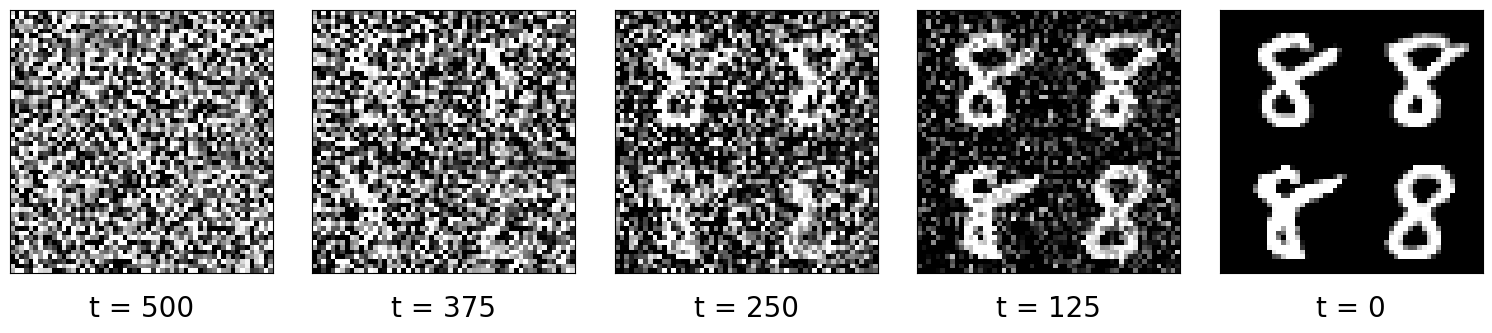

In [89]:
import matplotlib.pyplot as plt

n = len(images)

fig, axes = plt.subplots(1, n, figsize=(3.8*n, 4.5))

if n == 1:
    axes = [axes]

for i, (ax, img) in enumerate(zip(axes, images)):
    ax.imshow(img, cmap="gray")

    # Remove ticks but keep clean frame spacing
    ax.set_xticks([])
    ax.set_yticks([])

    # Caption under plot
    ax.set_title(f"t = {([500, 375, 250, 125, 0])[i]}", y=-0.2, fontsize=20)

# Better spacing between plots + room for captions
plt.subplots_adjust(wspace=0.15, bottom=0.25)

plt.show()